# Experiment No. 10: Single-Layer Artificial Neural Network

## Aim
To build and implement a single-layer Artificial Neural Network (ANN) using Python to solve a simple classification problem.

## Objectives
1. To understand the basic structure and working of a single-layer ANN.
2. To implement a single-layer ANN using Python and NumPy.
3. To train the network and predict the class of new data.
4. To evaluate the performance of the trained neural network.

## Relevance
Artificial Neural Networks are used to recognize patterns and solve classification problems. A single-layer ANN is a simple neural network that helps us understand the basic principles of neural learning. It is useful for simple classification tasks and provides a foundation for understanding more complex deep learning models.

## Theory

An Artificial Neural Network (ANN) is a computational model inspired by the working of the human brain. It consists of interconnected processing units called neurons that learn patterns from data by adjusting weights and biases.

### Single-Layer ANN
A single-layer ANN consists of an input layer and an output layer, without any hidden layer. The input features are multiplied by their corresponding weights, and a bias is added to calculate the weighted sum. An activation function then produces the output.

### Main Components
1. **Input:** The features supplied to the network.
2. **Weights:** Values that determine the importance of each input feature.
3. **Bias:** An additional value that helps the neuron adjust its output.
4. **Weighted Sum:** The sum of the input features multiplied by their corresponding weights, plus the bias.
5. **Activation Function:** Converts the weighted sum into an output. In this experiment, the sigmoid function is used.
6. **Output:** The predicted class of the input data.

### Sigmoid Activation Function
The sigmoid function converts a numerical value into a probability between 0 and 1.

Formula:

$$
\sigma(z) = \frac{1}{1 + e^{-z}}
$$

Here, $z$ represents the weighted sum of the inputs and bias.

For binary classification, a predicted probability of 0.5 or greater is classified as class 1, while a probability below 0.5 is classified as class 0.

### Working of a Single-Layer ANN
1. Provide input features to the network.
2. Multiply the input features by their corresponding weights.
3. Add the bias to calculate the weighted sum.
4. Apply the sigmoid activation function to obtain the predicted probability.
5. Compare the predictions with the actual class labels.
6. Calculate the error and update the weights and bias during training.
7. Repeat the process until the model learns the patterns in the training data.
8. Use the trained network to predict classes for new data.

### Training and Loss Function
The network learns by adjusting its weights and bias to reduce prediction errors. Gradient descent is used to update these parameters, while binary cross-entropy measures the difference between actual labels and predicted probabilities.

The binary cross-entropy loss function is:

$$
L = -\frac{1}{N}\sum_{i=1}^{N}
\left[y_i\log(p_i) + (1-y_i)\log(1-p_i)\right]
$$

Where:
- $N$ is the number of training samples.
- $y_i$ is the actual class label.
- $p_i$ is the predicted probability of class 1.
- $L$ is the average loss.

A lower loss indicates that the predicted probabilities are closer to the actual labels.

## Dataset Used
A small, artificially generated binary classification dataset containing two numerical input features and two possible class labels (0 and 1) will be used. NumPy will generate the data, and the neural network will be implemented from scratch without using a deep learning library.

## Step 1: Generate the Dataset

We use NumPy to generate a dataset containing two input features and binary class labels.

- **X1 and X2:** Input features.
- **Y:** Actual class labels (0 or 1).
- **Number of samples:** 200.

The dataset will contain two classes that can be separated using a straight decision boundary. This makes it suitable for demonstrating a single-layer neural network.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Set random seed for reproducible results
np.random.seed(42)

# Generate input features
X = np.random.randn(200, 2)

# Generate binary class labels
y = (X[:, 0] + X[:, 1] > 0).astype(int)

# Display the first five samples
dataset = pd.DataFrame(X, columns=["X1", "X2"])
dataset["Class"] = y

print("First five samples:")
print(dataset.head())

print("\nDataset shape:", X.shape)
print("Number of class 0 samples:", np.sum(y == 0))
print("Number of class 1 samples:", np.sum(y == 1))

First five samples:
         X1        X2  Class
0  0.496714 -0.138264      1
1  0.647689  1.523030      1
2 -0.234153 -0.234137      0
3  1.579213  0.767435      1
4 -0.469474  0.542560      1

Dataset shape: (200, 2)
Number of class 0 samples: 100
Number of class 1 samples: 100


## Step 2: Visualize and Split the Dataset

Data visualization helps us understand how the two classes are distributed.

We will use a scatter plot to display the input features:
- X1 is plotted on the horizontal axis.
- X2 is plotted on the vertical axis.
- Different colors represent class 0 and class 1.

Next, we will divide the dataset into:
- **Training set (80%):** Used to train the neural network.
- **Testing set (20%):** Used to evaluate the trained network on unseen data.

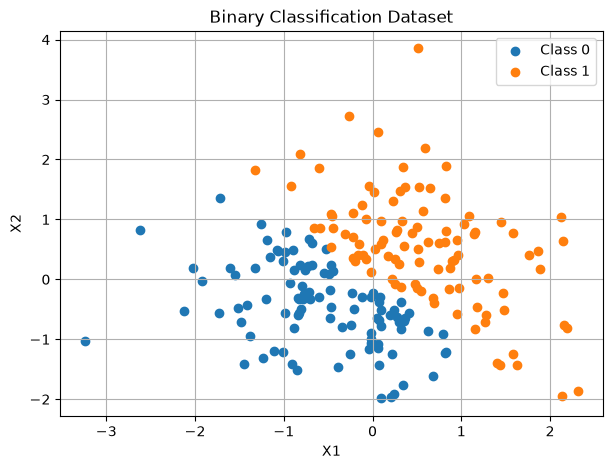

In [2]:
# Visualize the two classes
plt.figure(figsize=(7, 5))

plt.scatter(X[y == 0, 0], X[y == 0, 1], label="Class 0")
plt.scatter(X[y == 1, 0], X[y == 1, 1], label="Class 1")

plt.xlabel("X1")
plt.ylabel("X2")
plt.title("Binary Classification Dataset")
plt.legend()
plt.grid(True)
plt.show()

In [3]:
# Shuffle the dataset and split it into training and testing sets
indices = np.random.permutation(len(X))

split_index = int(0.8 * len(X))

train_indices = indices[:split_index]
test_indices = indices[split_index:]

X_train = X[train_indices]
X_test = X[test_indices]

y_train = y[train_indices]
y_test = y[test_indices]

print("Training samples:", len(X_train))
print("Testing samples:", len(X_test))
print("Training labels:", len(y_train))
print("Testing labels:", len(y_test))

Training samples: 160
Testing samples: 40
Training labels: 160
Testing labels: 40


## Step 3: Implement the Sigmoid Activation Function

The sigmoid function converts the weighted sum of inputs into a probability between 0 and 1.

Formula:

σ(z) = 1 / (1 + e^(-z))

A probability greater than or equal to 0.5 represents class 1, while a probability below 0.5 represents class 0.

We implement the sigmoid function using NumPy.

In [4]:
# Define the sigmoid activation function
def sigmoid(z):
    z = np.clip(z, -500, 500)
    return 1 / (1 + np.exp(-z))


# Test the sigmoid function
test_values = np.array([-2, -1, 0, 1, 2])

print("Input values:", test_values)
print("Sigmoid outputs:", sigmoid(test_values))

Input values: [-2 -1  0  1  2]
Sigmoid outputs: [0.11920292 0.26894142 0.5        0.73105858 0.88079708]


## Step 4: Initialize the Single-Layer Neural Network

The neural network contains two input features and one output neuron. It has no hidden layer.

The weighted sum is calculated as:

z = XW + b

The sigmoid function converts this weighted sum into a probability:

p = σ(z)

Where:
- X represents the input features.
- W represents the weights.
- b represents the bias.
- p represents the predicted probability.

The weights and bias are initially set to zero. During training, gradient descent updates them to reduce the prediction error.

In [7]:
# Initialize weights and bias
n_features = X_train.shape[1]

weights = np.zeros((n_features, 1))
bias = 0.0

# Convert labels into column vectors
y_train_col = y_train.reshape(-1, 1)
y_test_col = y_test.reshape(-1, 1)

print("Initial weights:\n", weights)
print("Initial bias:", bias)
print("Number of input features:", n_features)

Initial weights:
 [[0.]
 [0.]]
Initial bias: 0.0
Number of input features: 2


## Step 5: Train the Neural Network Using Gradient Descent

Training allows the neural network to learn the relationship between input features and class labels.

The training process follows these steps:

1. Calculate the weighted sum of the inputs.
2. Apply the sigmoid activation function.
3. Calculate the binary cross-entropy loss.
4. Calculate gradients for weights and bias.
5. Update the parameters using gradient descent.
6. Repeat the process for multiple epochs.

The weight and bias update rules are:

W = W - α(dW)

b = b - α(db)

Where α represents the learning rate.

The binary cross-entropy loss measures the difference between actual labels and predicted probabilities.

In [8]:
# Set training parameters
learning_rate = 0.1
epochs = 1000
n_samples = len(X_train)

loss_history = []

# Train the neural network
for epoch in range(epochs):

    # Forward propagation
    z = np.dot(X_train, weights) + bias
    predictions = sigmoid(z)

    # Calculate binary cross-entropy loss
    epsilon = 1e-8
    loss = -np.mean(
        y_train_col * np.log(predictions + epsilon)
        + (1 - y_train_col) * np.log(1 - predictions + epsilon)
    )

    loss_history.append(loss)

    # Calculate gradients
    dz = predictions - y_train_col
    dw = np.dot(X_train.T, dz) / n_samples
    db = np.mean(dz)

    # Update weights and bias
    weights -= learning_rate * dw
    bias -= learning_rate * db

    # Display progress
    if (epoch + 1) % 200 == 0:
        print(f"Epoch {epoch + 1}, Loss: {loss:.4f}")

print("\nTraining completed.")
print("Final weights:\n", weights)
print("Final bias:", bias)

Epoch 200, Loss: 0.2234
Epoch 400, Loss: 0.1679
Epoch 600, Loss: 0.1422
Epoch 800, Loss: 0.1263
Epoch 1000, Loss: 0.1152

Training completed.
Final weights:
 [[4.0849616 ]
 [3.69135096]]
Final bias: -0.018515948035592995


## Step 6: Visualize the Training Loss

The loss graph shows how the prediction error changes during training.

A decreasing loss indicates that the neural network is learning to predict the training labels more accurately.

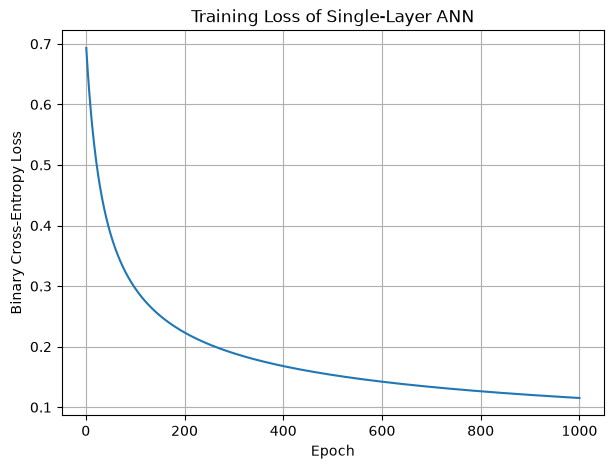

In [9]:
# Plot training loss
plt.figure(figsize=(7, 5))

plt.plot(range(1, epochs + 1), loss_history)

plt.xlabel("Epoch")
plt.ylabel("Binary Cross-Entropy Loss")
plt.title("Training Loss of Single-Layer ANN")
plt.grid(True)
plt.show()

## Step 7: Predict Class Labels

After training, the learned weights and bias are used to predict the class of each input sample.

The sigmoid function produces a probability between 0 and 1.

We use a threshold of 0.5:
- Probability >= 0.5: Class 1
- Probability < 0.5: Class 0

In [10]:
# Predict probabilities for the test dataset
test_probabilities = sigmoid(np.dot(X_test, weights) + bias)

# Convert probabilities into class labels
y_pred = (test_probabilities >= 0.5).astype(int).flatten()

# Display predictions
results = pd.DataFrame({
    "Actual Class": y_test,
    "Predicted Class": y_pred,
    "Predicted Probability": test_probabilities.flatten()
})

print(results.head(10))

   Actual Class  Predicted Class  Predicted Probability
0             1                1               0.872127
1             1                1               0.999910
2             1                1               0.999752
3             1                1               0.999759
4             0                0               0.006680
5             0                0               0.296594
6             0                0               0.002115
7             0                0               0.000024
8             1                1               0.999985
9             1                1               0.987418


## Step 8: Evaluate the Neural Network

We evaluate the trained neural network using classification accuracy.

Accuracy measures the percentage of test samples classified correctly.

Formula:

Accuracy = (Correct Predictions / Total Predictions) × 100

A higher accuracy indicates that the network correctly classifies more test samples.

In [11]:
# Calculate classification accuracy
correct_predictions = np.sum(y_pred == y_test)
accuracy = (correct_predictions / len(y_test)) * 100

print("Total test samples:", len(y_test))
print("Correct predictions:", correct_predictions)
print("Incorrect predictions:", len(y_test) - correct_predictions)
print(f"Classification Accuracy: {accuracy:.2f}%")

Total test samples: 40
Correct predictions: 40
Incorrect predictions: 0
Classification Accuracy: 100.00%


## Step 9: Predict the Class of New Data

The trained neural network can predict the class of a new sample that was not used during training.

We provide two input features and use the learned weights and bias to calculate the predicted probability and class label.

In [12]:
# Define a new sample with two input features
new_sample = np.array([[1.0, 0.5]])

# Predict its probability and class
new_probability = sigmoid(np.dot(new_sample, weights) + bias)
new_class = int(new_probability[0, 0] >= 0.5)

print("New sample:", new_sample)
print(f"Predicted probability: {new_probability[0, 0]:.4f}")
print("Predicted class:", new_class)

New sample: [[1.  0.5]]
Predicted probability: 0.9973
Predicted class: 1


## Conclusion

A single-layer Artificial Neural Network was successfully implemented using Python and NumPy for a binary classification problem.

The network used two input features, weights, a bias, and the sigmoid activation function. Gradient descent was used to train the network by minimizing binary cross-entropy loss.

The trained model predicted class labels for test samples and new input data. Its performance was evaluated using classification accuracy.

Thus, the experiment demonstrated the basic working, training, and prediction process of a single-layer ANN without using a deep learning library.